# Week 11 - Clustering, Part 2: DBSCAN and Hierarchical Agglomerative Clustering

Week 10's K-Means needs *k* in advance, assumes round clusters of similar size, and must put every point in some cluster. This week's two methods drop those assumptions in different ways.

* **DBSCAN** (density-based spatial clustering of applications with noise) has no *k*. A point is a **core point** if at least `min_samples` points lie within distance `eps` of it; clusters are chains of core points plus their neighbors, and anything not reachable is labeled **noise** (-1). It can find odd-shaped clusters and refuses to force outliers into a group.
* **Hierarchical agglomerative clustering (HAC)** starts with every point in its own cluster and repeatedly merges the two closest clusters. The **linkage** defines "closest": **single** (nearest pair of points), **complete** (farthest pair), **average** (mean of all pairs), or **Ward** (the merge that increases within-cluster variance the least, the same objective as K-Means). The full merge history is a **dendrogram**; cutting it at a height gives a flat clustering for any *k*.

| Dataset | What gets clustered | Question |
|---|---|---|
| E-commerce | 3,312 orders on log(`Sales`), `Quantity`, `Discount` (standardized, as in Week 10) | Does DBSCAN's noise label find unusual orders? Which linkage recovers the money-losing group? |
| Instacart | the same 70 aisle profiles as Week 10 | What does the aisle dendrogram look like, and does density-based clustering work on 70 points? |
| Amazon reviews | TF-IDF -> 100-d SVD, unit length (Week 10), cosine distance | Can DBSCAN find dense groups of near-identical reviews? |

As in Week 10, labels (profitable, reordered, negative) are only used **after** clustering, to describe the groups.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
np.random.seed(42)
BLUE, ORANGE, GREY, GREEN, PURPLE = "#2a78d6", "#eb6834", "#8a8984", "#1b9e77", "#7b4fb8"
PALETTE = [BLUE, ORANGE, GREEN, PURPLE, "#c9a227", "#d6457a", "#3fb0c8", "#5c5c5c"]

def k_distance(A, k, metric="euclidean"):
    # distance from every point to its k-th nearest neighbor (the point itself counts as the first), sorted
    d = NearestNeighbors(n_neighbors=k, metric=metric).fit(A).kneighbors(A)[0][:, -1]
    return np.sort(d)

## Part 0 - Warm-up: where each method wins

Two interleaved half-moons. K-Means and Ward linkage both look for compact, round groups, so they should cut each moon in half. DBSCAN and single linkage follow chains of nearby points, so they should trace the moons.

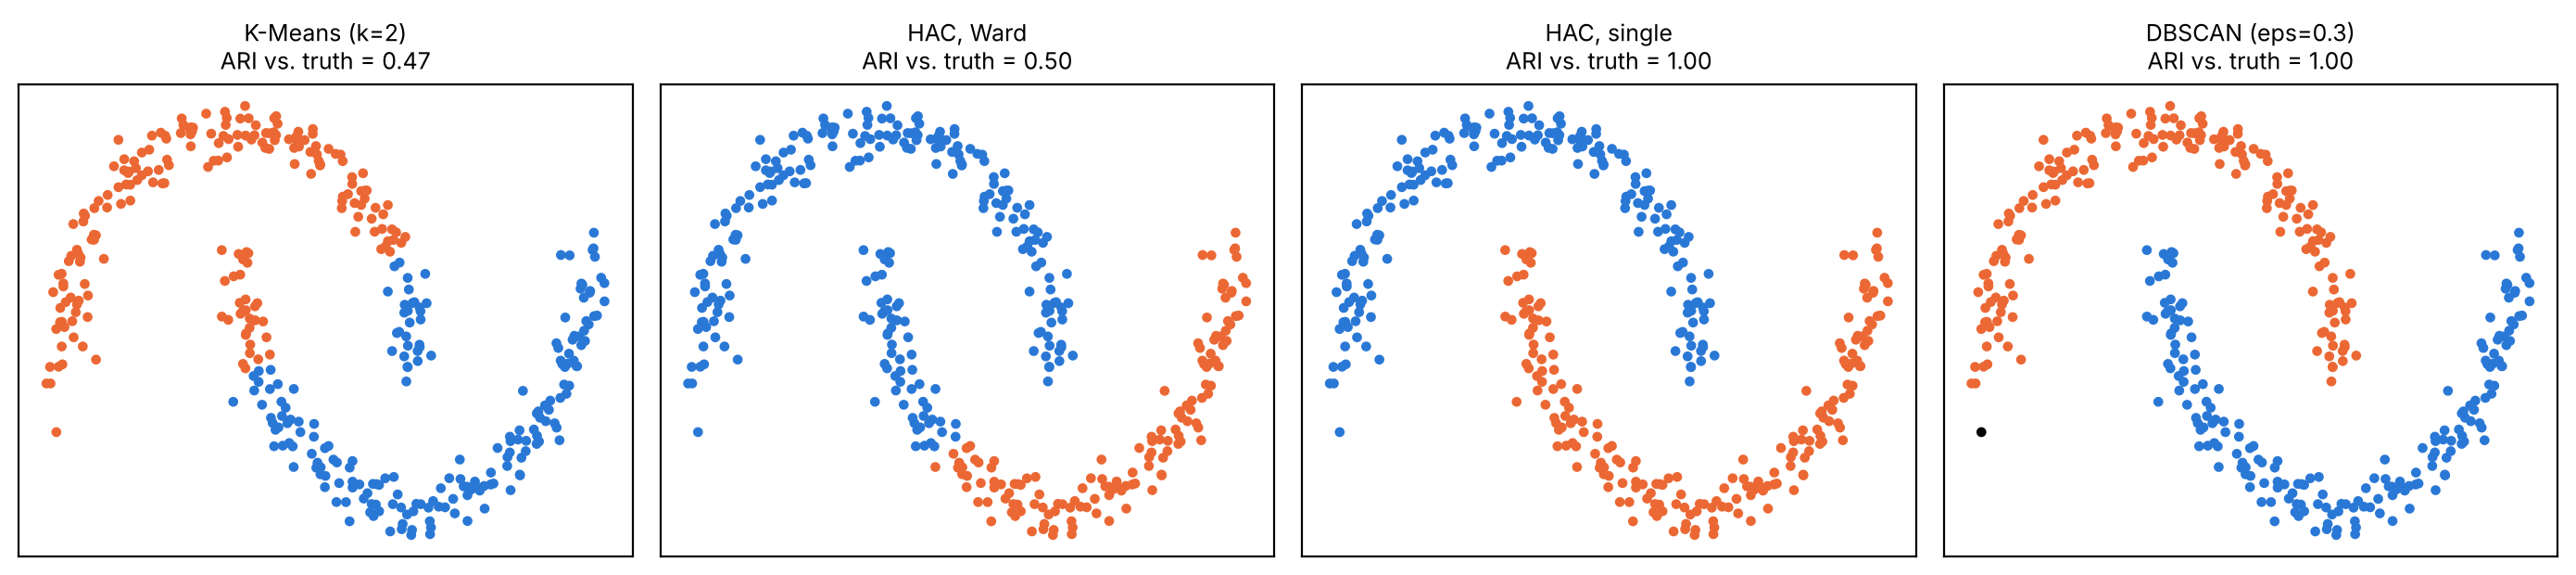

In [2]:
Xm, ym = make_moons(n_samples=400, noise=0.06, random_state=42)
Xm = StandardScaler().fit_transform(Xm)
methods = {
    "K-Means (k=2)": KMeans(2, n_init=10, random_state=42).fit_predict(Xm),
    "HAC, Ward": AgglomerativeClustering(2, linkage="ward").fit_predict(Xm),
    "HAC, single": AgglomerativeClustering(2, linkage="single").fit_predict(Xm),
    "DBSCAN (eps=0.3)": DBSCAN(eps=0.3, min_samples=5).fit_predict(Xm),
}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, (name, lab) in zip(ax, methods.items()):
    a.scatter(Xm[:, 0], Xm[:, 1], c=[PALETTE[l] if l >= 0 else "black" for l in lab], s=8)
    a.set_title(f"{name}\nARI vs. truth = {adjusted_rand_score(ym, lab):.2f}", fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Part A - E-commerce orders

### A1. What the EDA says about density

The features are standardized exactly as in Week 10. One fact from the EDA matters a lot for DBSCAN: `Discount` takes only 12 distinct values and `Quantity` only 14, so the orders sit on a grid and many orders share an exact location. Any `eps` smaller than the grid spacing will find dozens of tiny "clusters" that are really just identical (Discount, Quantity) pairs with similar sales.

In [3]:
df = pd.read_csv("ecommerce_data.csv")
profitable = (df["Profit"] > 0).astype(int).values
feats = pd.DataFrame({"log_Sales": np.log1p(df["Sales"]), "Quantity": df["Quantity"], "Discount": df["Discount"]})
A = StandardScaler().fit_transform(feats)
print(f"{len(A)} orders, {len(np.unique(A, axis=0))} distinct points; Discount has {df.Discount.nunique()} values, Quantity {df.Quantity.nunique()}")
print("distinct Discount values:", sorted(df.Discount.unique()))

3312 orders, 2742 distinct points; Discount has 12 values, Quantity 14
distinct Discount values: [np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


### A2. Choosing `eps` with the k-distance plot

The standard recipe (Ester et al., 1996): pick `min_samples`, compute each point's distance to its `min_samples`-th nearest neighbor, sort, and look for the knee where the curve turns sharply upward. Points left of the knee sit in dense regions; points right of it are candidates for noise. A common rule of thumb is `min_samples` >= number of features + 1 (here, 4), and larger values give more stable cores; I compare 5, 10, and 20.

min_samples= 5: k-distance percentiles 50/90/95/99 = [0.033 0.363 0.482 0.797]
min_samples=10: k-distance percentiles 50/90/95/99 = [0.077 0.482 0.562 1.026]
min_samples=20: k-distance percentiles 50/90/95/99 = [0.162 0.586 0.757 1.315]


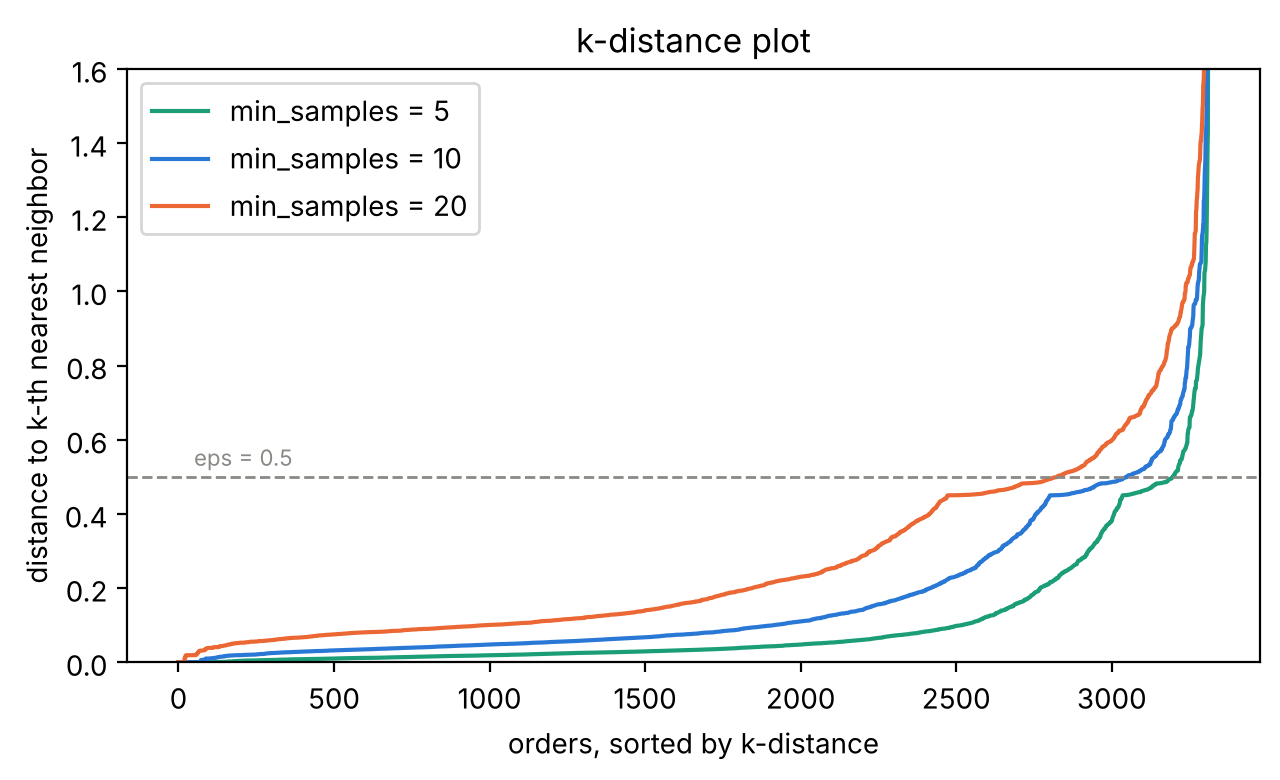

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for ms, c in [(5, GREEN), (10, BLUE), (20, ORANGE)]:
    d = k_distance(A, ms); ax.plot(d, color=c, label=f"min_samples = {ms}")
    print(f"min_samples={ms:2d}: k-distance percentiles 50/90/95/99 = {np.percentile(d, [50, 90, 95, 99]).round(3)}")
ax.axhline(0.5, color=GREY, ls="--", lw=1); ax.text(50, 0.53, "eps = 0.5", color=GREY, fontsize=8)
ax.set_ylim(0, 1.6); ax.set_xlabel("orders, sorted by k-distance"); ax.set_ylabel("distance to k-th nearest neighbor"); ax.set_title("k-distance plot"); ax.legend()
plt.tight_layout(); plt.show()

### A3. Sweeping `eps` and `min_samples`

For each pair: number of clusters, share of orders labeled noise, silhouette on the non-noise points, and the profitable rate of the noise.

In [5]:
rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    for ms in [5, 10, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(A)
        nc, m = lab.max() + 1, lab != -1
        rows.append({"eps": eps, "min_samples": ms, "clusters": nc, "noise_share": (~m).mean(),
                     "silhouette_non_noise": silhouette_score(A[m], lab[m]) if nc > 1 else np.nan,
                     "largest_cluster_share": np.bincount(lab[m]).max() / len(lab) if m.any() else 0,
                     "noise_profitable_rate": profitable[~m].mean() if (~m).any() else np.nan})
db_grid = pd.DataFrame(rows)
print(db_grid.round(3).to_string(index=False))

 eps  min_samples  clusters  noise_share  silhouette_non_noise  largest_cluster_share  noise_profitable_rate
 0.2            5        44        0.136                -0.002                  0.110                  0.327
 0.2           10        24        0.220                 0.019                  0.108                  0.434
 0.2           20        16        0.369                 0.039                  0.105                  0.588
 0.3            5        48        0.089                 0.044                  0.110                  0.274
 0.3           10        27        0.160                 0.052                  0.109                  0.328
 0.3           20        14        0.268                 0.086                  0.108                  0.470
 0.4            5        44        0.068                 0.047                  0.110                  0.237
 0.4           10        25        0.130                 0.063                  0.110                  0.252
 0.4           20  

### A4. The chosen DBSCAN model: `eps` = 0.5, `min_samples` = 10

`eps` = 0.5 sits at the knee of the `min_samples` = 10 curve (about its 90th percentile), and it is the smallest radius that stops the grid from shattering into dozens of clusters. Neighboring settings (0.5-0.6 with 10-20) give the same picture, which A6 checks more formally.

In [6]:
db = DBSCAN(eps=0.5, min_samples=10).fit(A)
lab_db = db.labels_
db_profile = df.assign(cluster=lab_db, profitable=profitable).groupby("cluster").agg(
    orders=("profitable", "size"), profitable_rate=("profitable", "mean"), mean_discount=("Discount", "mean"),
    min_discount=("Discount", "min"), max_discount=("Discount", "max"), median_sales=("Sales", "median"),
    max_sales=("Sales", "max"), mean_quantity=("Quantity", "mean"), total_profit=("Profit", "sum"))
db_profile["profit_per_order"] = db_profile.total_profit / db_profile.orders
print(db_profile.round(3).to_string())
print(f"\ncore points: {len(db.core_sample_indices_)} of {len(A)}")

noise = df[lab_db == -1]
print("\nWhat makes an order 'noise'? Discount values among noise orders:"); print(noise.Discount.value_counts().sort_index().to_string())
print(f"\nnoise orders with Sales > $1,000: {(noise.Sales > 1000).sum()}; with Quantity >= 10: {(noise.Quantity >= 10).sum()}")
print(f"share of ALL orders at discount 0.3-0.5 that are noise: {(lab_db[(df.Discount >= 0.3) & (df.Discount <= 0.5)] == -1).mean():.3f}")
print("\nlargest noise orders by sales:"); print(noise.sort_values("Sales", ascending=False)[["Sales", "Quantity", "Discount", "Profit", "Sub-Category"]].head(6).to_string())

         orders  profitable_rate  mean_discount  min_discount  max_discount  median_sales  max_sales  mean_quantity  total_profit  profit_per_order
cluster                                                                                                                                            
-1          130            0.269          0.502           0.0           0.8       214.164  13999.960          7.254     -12658.17           -97.371
 0         2965            0.890          0.100           0.0           0.5        59.760   5443.960          3.647     109460.23            36.917
 1          217            0.000          0.724           0.6           0.8         8.100     76.776          3.323      -3362.79           -15.497

core points: 3048 of 3312

What makes an order 'noise'? Discount values among noise orders:
Discount
0.00    14
0.10     2
0.15     1
0.20    13
0.30     4
0.40    19
0.45     1
0.50     9
0.60    11
0.70    29
0.80    27

noise orders with Sales > $1,000: 29

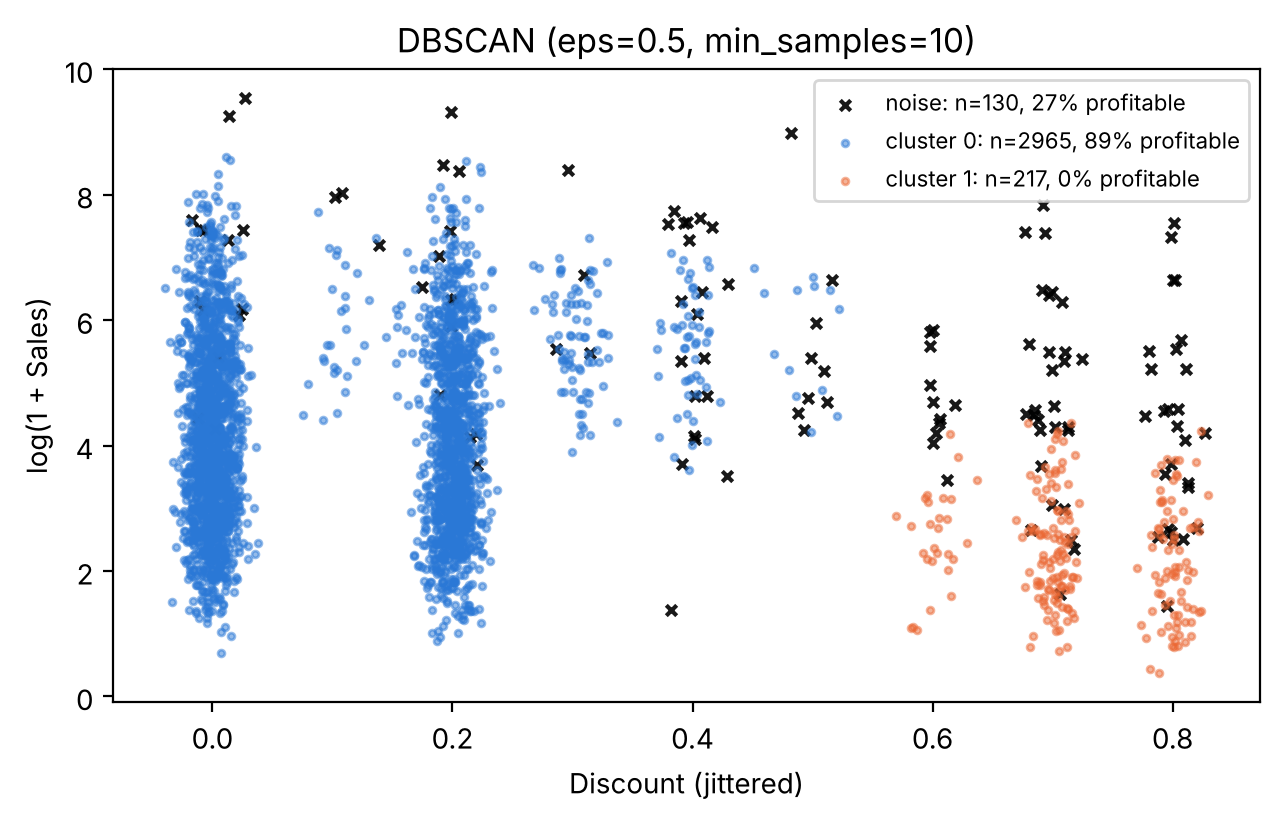

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
names = {-1: "noise", 0: "cluster 0", 1: "cluster 1"}
cols = {-1: "black", 0: BLUE, 1: ORANGE}
for c in sorted(set(lab_db)):
    m = lab_db == c
    ax.scatter(df.Discount[m] + np.random.default_rng(c + 5).normal(0, 0.012, m.sum()), np.log1p(df.Sales[m]), s=6 if c >= 0 else 14,
               alpha=0.5 if c >= 0 else 0.9, color=cols.get(c, GREY), marker="o" if c >= 0 else "x",
               label=f"{names.get(c, c)}: n={m.sum()}, {profitable[m].mean():.0%} profitable")
ax.set_xlabel("Discount (jittered)"); ax.set_ylabel("log(1 + Sales)"); ax.set_title("DBSCAN (eps=0.5, min_samples=10)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### A5. Hierarchical clustering: four linkages on the same orders

For each linkage I report the **cophenetic correlation** (how well the dendrogram's merge heights preserve the original pairwise distances; 1 = perfectly), the silhouette and cluster sizes when the tree is cut into *k* clusters, agreement with the Week 10 K-Means (k = 4) solution, and the lowest profitable rate of any cluster.

In [8]:
km4 = KMeans(4, n_init=10, random_state=42).fit_predict(A)
D = pdist(A)
links, rows = {}, []
for method in ["ward", "complete", "average", "single"]:
    Z = linkage(A, method=method); links[method] = Z
    coph = cophenet(Z, D)[0]
    for k in [2, 3, 4]:
        lab = fcluster(Z, k, criterion="maxclust")
        rows.append({"linkage": method, "cophenetic_r": coph, "k": k, "silhouette": silhouette_score(A, lab),
                     "sizes": sorted(np.bincount(lab)[1:].tolist(), reverse=True), "ARI_vs_KMeans4": adjusted_rand_score(km4, lab),
                     "lowest_profitable_rate": min(profitable[lab == c].mean() for c in np.unique(lab))})
hac_tbl = pd.DataFrame(rows)
print(hac_tbl.round(3).to_string(index=False))

 linkage  cophenetic_r  k  silhouette                 sizes  ARI_vs_KMeans4  lowest_profitable_rate
    ward         0.586  2       0.472           [3012, 300]           0.166                   0.003
    ward         0.586  3       0.279     [1750, 1262, 300]           0.481                   0.003
    ward         0.586  4       0.288 [1262, 931, 819, 300]           0.597                   0.003
complete         0.502  2       0.238           [2468, 844]           0.201                   0.790
complete         0.502  3       0.258     [1439, 1029, 844]           0.581                   0.709
complete         0.502  4       0.261 [1439, 1029, 755, 89]           0.603                   0.000
 average         0.768  2       0.571             [3308, 4]           0.001                   0.000
 average         0.768  3       0.461        [3012, 296, 4]           0.167                   0.000
 average         0.768  4       0.368   [2789, 296, 223, 4]           0.264                   0.000


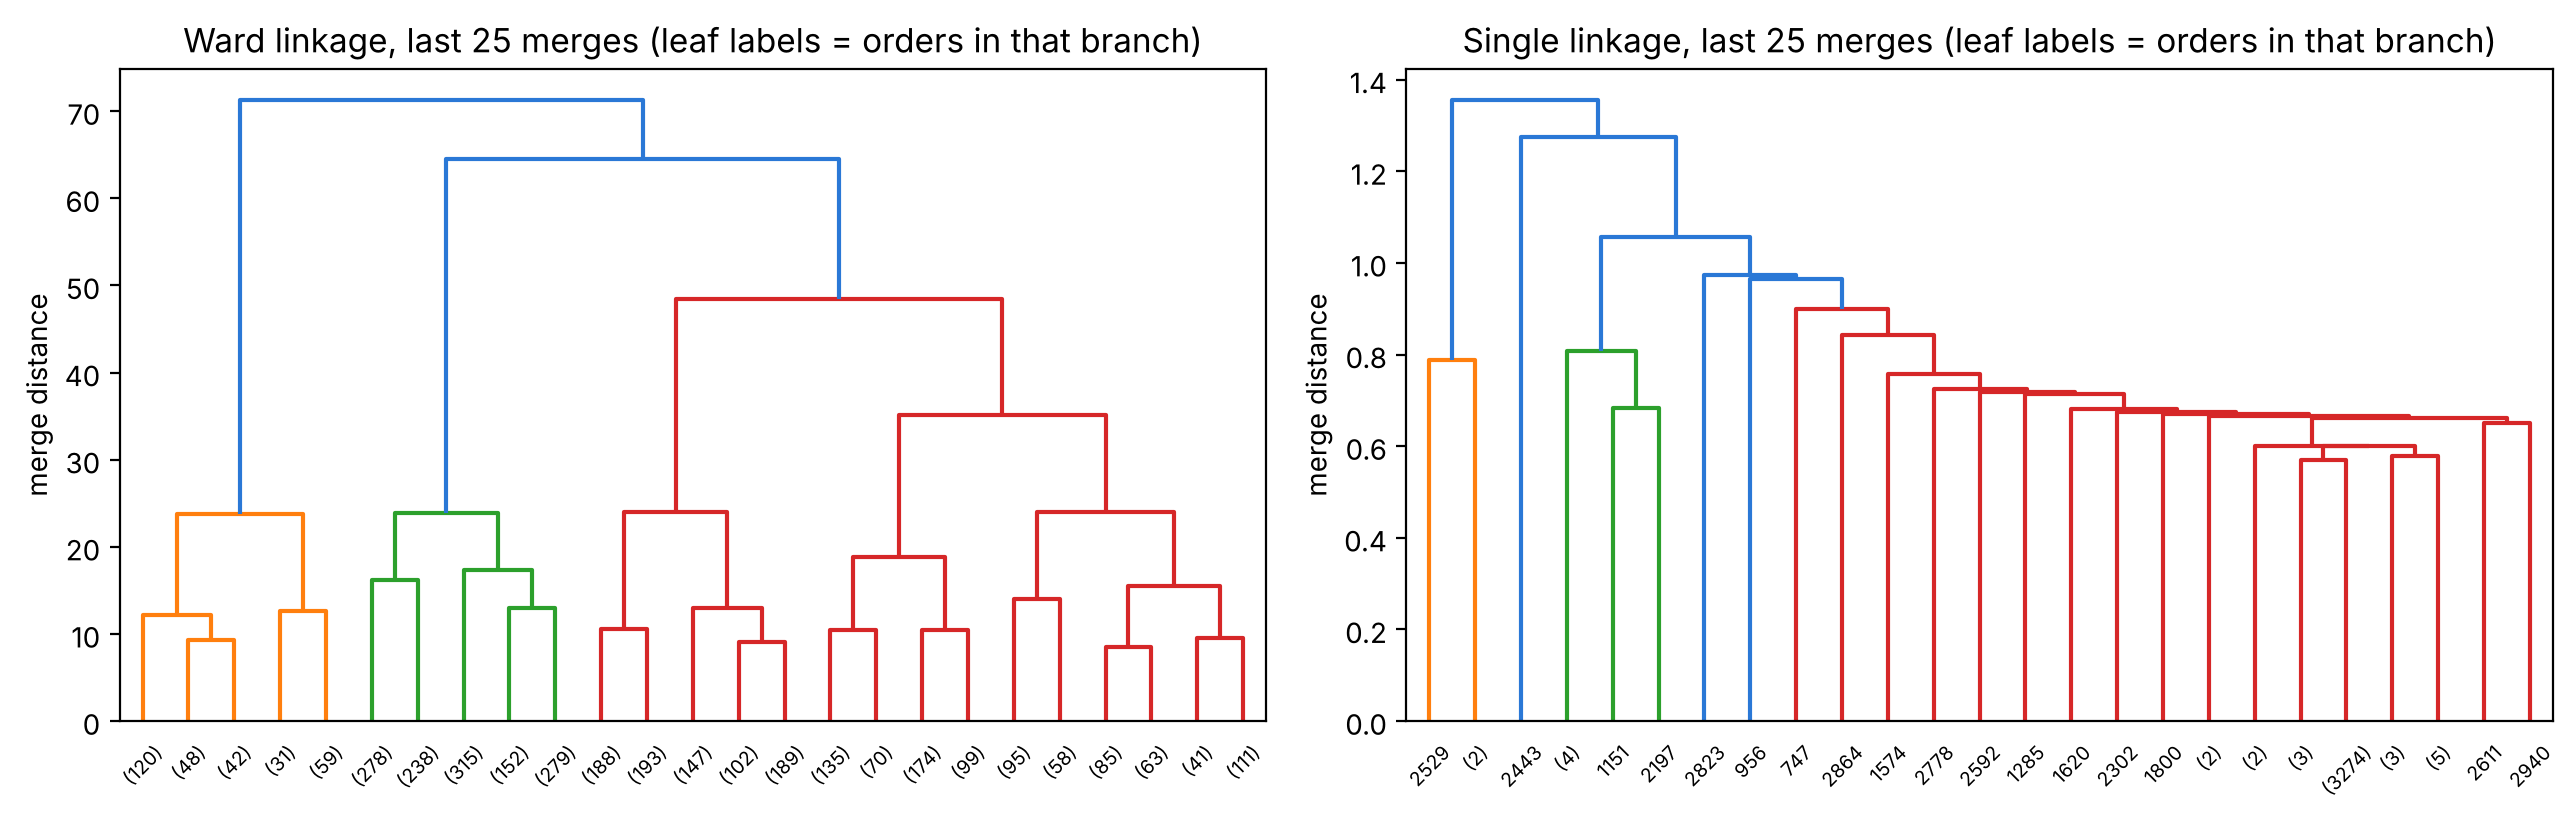

Ward, cut at k=2: small branch has 300 orders, discount 0.40-0.80, profitable rate 0.003, total profit $-31,926
Ward merge heights for the last 5 merges: [24.  35.2 48.4 64.5 71.3]


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, method in zip(ax, ["ward", "single"]):
    dendrogram(links[method], truncate_mode="lastp", p=25, ax=a, color_threshold=None, above_threshold_color=BLUE, show_leaf_counts=True, leaf_font_size=7)
    a.set_title(f"{method.capitalize()} linkage, last 25 merges (leaf labels = orders in that branch)"); a.set_ylabel("merge distance")
plt.tight_layout(); plt.show()

ward2 = fcluster(links["ward"], 2, criterion="maxclust")
small = np.argmin(np.bincount(ward2)[1:]) + 1
m = ward2 == small
print(f"Ward, cut at k=2: small branch has {m.sum()} orders, discount {df.Discount[m].min():.2f}-{df.Discount[m].max():.2f}, "
      f"profitable rate {profitable[m].mean():.3f}, total profit ${df.Profit[m].sum():,.0f}")
print(f"Ward merge heights for the last 5 merges: {links['ward'][-5:, 2].round(1)}")

### A6. Overfitting and stability

Neither method has a test set, so "overfitting" means finding structure that is really noise in this particular sample. I check it two ways:

1. **Parameter sensitivity**: does the DBSCAN result survive small changes in `eps` and `min_samples`?
2. **Subsampling**: re-run on 10 random 75% subsamples and compare with the full-data labels on the shared orders (ARI). A structure that is really in the data should come back each time.

In [10]:
ref = lab_db
sens = []
for eps in [0.45, 0.5, 0.55, 0.6]:
    for ms in [8, 10, 15, 20]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(A)
        hi = (l >= 0) & (df.Discount.values >= 0.6)
        sens.append({"eps": eps, "min_samples": ms, "clusters": l.max() + 1, "noise": (l == -1).sum(), "ARI_vs_chosen": adjusted_rand_score(ref, l)})
sens = pd.DataFrame(sens); print(sens.pivot(index="eps", columns="min_samples", values="ARI_vs_chosen").round(3))
print("\nclusters found:"); print(sens.pivot(index="eps", columns="min_samples", values="clusters"))

rng = np.random.default_rng(42); sub = {"DBSCAN (0.5, 10)": [], "HAC Ward, k=2": [], "HAC Ward, k=4": [], "HAC average, k=4": []}
ward4 = fcluster(links["ward"], 4, criterion="maxclust"); avg4 = fcluster(links["average"], 4, criterion="maxclust")
for r in range(10):
    idx = rng.choice(len(A), int(0.75 * len(A)), replace=False); As = A[idx]
    sub["DBSCAN (0.5, 10)"].append(adjusted_rand_score(lab_db[idx], DBSCAN(eps=0.5, min_samples=10).fit_predict(As)))
    Zs_w, Zs_a = linkage(As, "ward"), linkage(As, "average")
    sub["HAC Ward, k=2"].append(adjusted_rand_score(ward2[idx], fcluster(Zs_w, 2, "maxclust")))
    sub["HAC Ward, k=4"].append(adjusted_rand_score(ward4[idx], fcluster(Zs_w, 4, "maxclust")))
    sub["HAC average, k=4"].append(adjusted_rand_score(avg4[idx], fcluster(Zs_a, 4, "maxclust")))
print("\nsubsample stability (mean / min ARI over 10 runs of 75%):")
for k, v in sub.items(): print(f"  {k:18s} {np.mean(v):.3f} / {np.min(v):.3f}")

min_samples     8      10     15     20
eps                                    
0.45         0.019  0.014 -0.000 -0.009
0.50         0.972  1.000  0.940  0.894
0.55         0.953  0.962  0.981  0.960
0.60         0.292  0.322  0.968  0.970

clusters found:
min_samples  8   10  15  20
eps                        
0.45         33  28  20  20
0.50          4   2   2   3
0.55          2   3   2   2
0.60          1   1   2   2



subsample stability (mean / min ARI over 10 runs of 75%):
  DBSCAN (0.5, 10)   0.952 / 0.940
  HAC Ward, k=2      0.866 / 0.009
  HAC Ward, k=4      0.519 / 0.363
  HAC average, k=4   0.617 / 0.078


## Part B - Instacart aisles: the dendrogram

Same 70 aisle profiles as Week 10 (aisles with at least 40 rows; reorder rate, mean cart position, mean hour, mean days since prior order, median order number; standardized). With 70 points the full dendrogram is readable, so every leaf is labeled with its aisle.

In [11]:
ins = pd.read_csv("insta_df_sample.csv")
aisles = (ins.groupby(["aisle", "department"])
             .agg(rows=("reordered", "size"), reorder_rate=("reordered", "mean"), cart_position=("add_to_cart_order", "mean"),
                  hour=("order_hour_of_day", "mean"), days_since_prior=("days_since_prior_order", "mean"), order_number=("order_number", "median"))
             .reset_index())
aisles = aisles[aisles.rows >= 40].reset_index(drop=True)
af = ["reorder_rate", "cart_position", "hour", "days_since_prior", "order_number"]
Ai = StandardScaler().fit_transform(aisles[af])
km_i = KMeans(3, n_init=20, random_state=42).fit_predict(Ai)       # Week 10 solution, for comparison
rows, links_i = [], {}
for method in ["ward", "complete", "average", "single"]:
    Z = linkage(Ai, method); links_i[method] = Z
    for k in [3, 4]:
        lab = fcluster(Z, k, "maxclust")
        rows.append({"linkage": method, "cophenetic_r": cophenet(Z, pdist(Ai))[0], "k": k, "silhouette": silhouette_score(Ai, lab),
                     "sizes": sorted(np.bincount(lab)[1:].tolist(), reverse=True), "ARI_vs_KMeans3": adjusted_rand_score(km_i, lab)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 linkage  cophenetic_r  k  silhouette            sizes  ARI_vs_KMeans3
    ward         0.447  3       0.186     [33, 24, 13]           0.622
    ward         0.447  4       0.181 [24, 20, 13, 13]           0.581
complete         0.446  3       0.124     [31, 25, 14]           0.301
complete         0.446  4       0.130  [25, 22, 14, 9]           0.256
 average         0.641  3       0.160       [68, 1, 1]           0.000
 average         0.641  4       0.093    [67, 1, 1, 1]          -0.004
  single         0.533  3       0.174       [68, 1, 1]          -0.008
  single         0.533  4       0.093    [67, 1, 1, 1]          -0.004


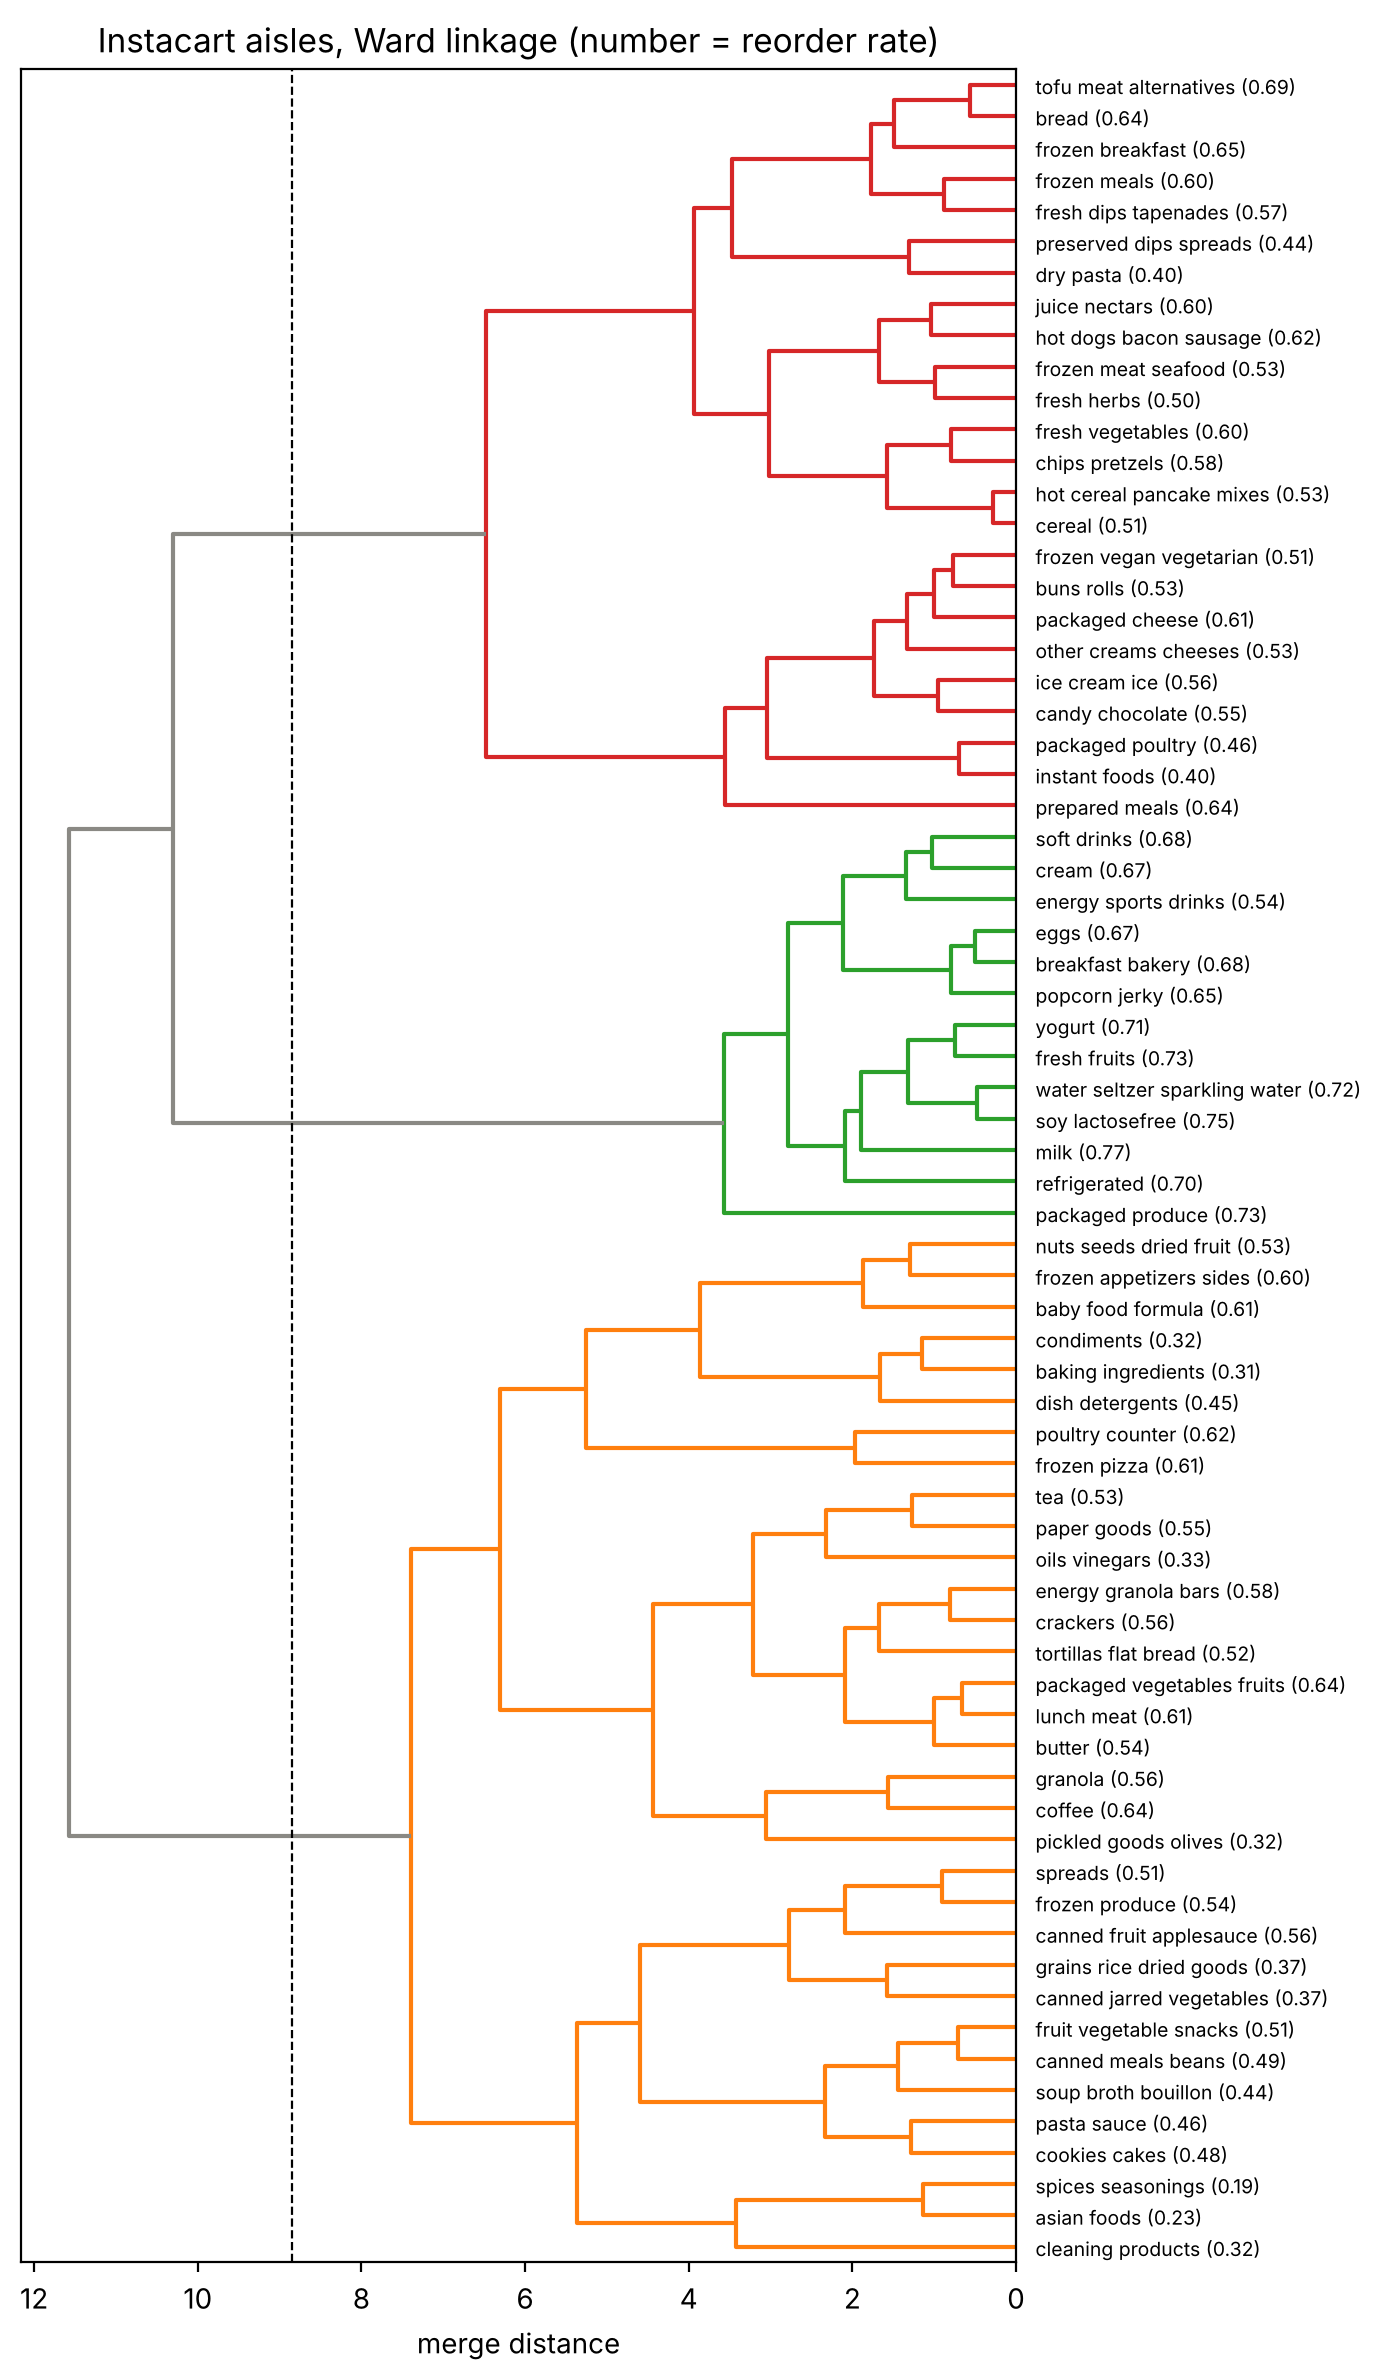

     reorder_rate  cart_position   hour  days_since_prior  order_number    rows  aisles
hac                                                                                    
2            0.69           6.61  13.47             11.01         11.85  359.69      13
3            0.55           8.72  13.68             11.94          9.58  204.00      24
1            0.48           9.42  13.38             10.67         11.80  133.94      33


In [12]:
Zw = links_i["ward"]
cut = (Zw[-3, 2] + Zw[-2, 2]) / 2            # height that leaves 3 clusters
lab_i = fcluster(Zw, 3, "maxclust"); aisles["hac"] = lab_i
fig, ax = plt.subplots(figsize=(7, 12))
dendrogram(Zw, labels=[f"{a} ({r:.2f})" for a, r in zip(aisles.aisle, aisles.reorder_rate)], orientation="left", leaf_font_size=7,
           color_threshold=cut, above_threshold_color=GREY, ax=ax)
ax.axvline(cut, color="black", ls="--", lw=0.8)
ax.set_title("Instacart aisles, Ward linkage (number = reorder rate)"); ax.set_xlabel("merge distance")
plt.tight_layout(); plt.show()
print(aisles.groupby("hac")[af + ["rows"]].mean().round(2).assign(aisles=aisles.groupby("hac").size()).sort_values("reorder_rate", ascending=False).to_string())

### B2. DBSCAN on 70 aisles

With only 70 points in 5 dimensions, there may be no dense core at all.

In [13]:
d5 = k_distance(Ai, 5)
print("5th-neighbor distance percentiles 10/50/90:", np.percentile(d5, [10, 50, 90]).round(2))
for eps in [0.8, 1.0, 1.2, 1.5, 2.0]:
    l = DBSCAN(eps=eps, min_samples=5).fit_predict(Ai)
    print(f"eps={eps}: clusters {l.max() + 1}, noise {(l == -1).sum()} of {len(l)}, cluster sizes {np.bincount(l[l >= 0]).tolist() if (l >= 0).any() else []}")

5th-neighbor distance percentiles 10/50/90: [1.13 1.41 2.18]
eps=0.8: clusters 0, noise 70 of 70, cluster sizes []
eps=1.0: clusters 1, noise 65 of 70, cluster sizes [5]
eps=1.2: clusters 1, noise 39 of 70, cluster sizes [31]
eps=1.5: clusters 1, noise 20 of 70, cluster sizes [50]
eps=2.0: clusters 1, noise 6 of 70, cluster sizes [64]


## Part C - Amazon reviews: DBSCAN with cosine distance

Same text representation as Week 10 (TF-IDF, 100 SVD components, each row scaled to length 1, empty reviews removed). DBSCAN runs directly on cosine distance, `min_samples` = 10.

In [14]:
a = pd.read_csv("amazon_review_data.csv")
a = a[a["rating"] != 3].copy()
a["negative"] = (a["rating"] <= 2).astype(int)
a["full"] = a["title"].fillna("") + ". " + a["text"].fillna("")
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)
T = tfidf.fit_transform(a["full"]); keep = T.getnnz(axis=1) > 0
T, a = T[keep], a[keep].reset_index(drop=True)
Z = normalize(TruncatedSVD(n_components=100, random_state=42).fit_transform(T))
print(Z.shape, "| 10th-neighbor cosine distance percentiles 10/50/90:", np.percentile(k_distance(Z, 10, "cosine"), [10, 50, 90]).round(3))

rows, text_labels = [], {}
for eps in [0.1, 0.2, 0.3, 0.4, 0.5]:
    l = DBSCAN(eps=eps, min_samples=10, metric="cosine").fit_predict(Z); text_labels[eps] = l
    sizes = np.bincount(l[l >= 0]) if (l >= 0).any() else np.array([0])
    rows.append({"eps": eps, "clusters": l.max() + 1, "noise_share": (l == -1).mean(), "largest_cluster": sizes.max(),
                 "max_cluster_negative_rate": max([a.negative[l == c].mean() for c in range(l.max() + 1)] or [np.nan])})
print(pd.DataFrame(rows).round(3).to_string(index=False))

(9355, 100) | 10th-neighbor cosine distance percentiles 10/50/90: [0.162 0.347 0.462]


 eps  clusters  noise_share  largest_cluster  max_cluster_negative_rate
 0.1        30        0.930               69                      1.000
 0.2        63        0.734              163                      1.000
 0.3        17        0.381             5150                      0.769
 0.4         1        0.076             8646                      0.121
 0.5         1        0.001             9345                      0.124


In [15]:
l = text_labels[0.2]
tab = pd.DataFrame({"cluster": range(l.max() + 1), "reviews": [(l == c).sum() for c in range(l.max() + 1)],
                    "negative_rate": [a.negative[l == c].mean() for c in range(l.max() + 1)]})
print(f"eps=0.2: {len(tab)} clusters; clusters that are >= 80% negative: {(tab.negative_rate >= 0.8).sum()}; "
      f"reviews in them: {tab.reviews[tab.negative_rate >= 0.8].sum()}")
print(f"clusters with 0% negative: {(tab.negative_rate == 0).sum()} ({tab.reviews[tab.negative_rate == 0].sum()} reviews)")
for c in tab.sort_values("negative_rate", ascending=False).cluster.head(2):
    print(f"\ncluster {c}: {(l == c).sum()} reviews, {a.negative[l == c].mean():.0%} negative. Examples:")
    for t in a.full[l == c].str.slice(0, 90).head(4): print("   ", t)

eps=0.2: 63 clusters; clusters that are >= 80% negative: 4; reviews in them: 70
clusters with 0% negative: 22 (633 reviews)

cluster 60: 8 reviews, 100% negative. Examples:
    Does not work, car would not except, to cheap to bother returning.. Did no work on vehicle
    One Star. Card did not work!!!!
    no good. did not work like i was hoping for, idea lead me astray in what was to do.....
    Not good!. will be returning. !st out of package did not work properly!

cluster 2: 39 reviews, 97% negative. Examples:
    not what it claims to do. nothing special  unfortunately i waited too long to return them 
    Ineffective. A total waste of money.  I get better results using a tea bag to alleviate un
    waste of money. Plastic does not bend for matching your brows and will not lay against you
    worked. saved a lot of money


## Conclusions

**Toy data (Part 0).** On the half-moons, K-Means (ARI vs. the true moons 0.47) and Ward linkage (0.50) cut each moon in half because they look for compact, round groups. Single linkage (1.00) and DBSCAN (0.99) follow the chain of nearby points and recover the shapes. My e-commerce data is not moon-shaped, so this is the reason to try density methods, not a promise that they win.

**DBSCAN on orders: the grid matters more than the textbook recipe (A1-A3).** The 3,312 orders occupy only 2,742 distinct points, because `Discount` has 12 values and `Quantity` has 14. For every `eps` up to 0.4, DBSCAN shattered the data into 14-48 "clusters" that are just neighboring grid cells (silhouette on non-noise points between -0.002 and 0.090). At `eps` = 0.5 the picture snaps into place. The k-distance plot put the knee for `min_samples` = 10 at about 0.48 (90th percentile), so `eps` = 0.5 with `min_samples` = 10 was the natural choice: 2 clusters, 3.9% noise, non-noise silhouette 0.496.

**What DBSCAN found (A4).**
* **Cluster 1:** 217 orders, all at discount 0.6-0.8, **0% profitable**, -$3,363 in total.
* **Cluster 0:** 2,965 orders at discount 0-0.5, 89.0% profitable, +$109,460.
* **Noise:** 130 orders, 26.9% profitable, **-$12,658 in total, or -$97 per order**. That is six times worse per order than the high-discount cluster (-$15). The noise is where unusual combinations live: 29 orders over $1,000 (including all three copiers over $10,000), 36 orders with quantity 10 or more, and 19% of all orders in the sparse 0.3-0.5 discount range. One $8,000 Machines order at a 0.5 discount lost $3,840 by itself.

So DBSCAN adds something K-Means could not: K-Means forced these orders into the nearest cluster, while DBSCAN flags them as the small set worth a manual review. It also draws the "never profitable" boundary at 0.6, while K-Means (Week 10) and Ward put it at 0.4. Discounts of 0.4-0.5 are too sparse to form a dense group.

**Hierarchical clustering: the linkage changes everything (A5).**
* **Ward** cut at k = 2 isolated **300 orders at discount 0.4-0.8, 0.3% profitable, -$31,926**, the same group as the Week 10 K-Means cluster (silhouette 0.472).
* **Complete** linkage produced balanced but less useful groups: at k = 2 and 3 no cluster fell below 70.9% profitable.
* **Average and single** linkage peeled off 3-4 extreme orders (very high quantities, one $8,000 machine) and left about 3,300 orders in one cluster. Single linkage is the textbook *chaining* failure: one chain of close neighbors links almost everything together.

**Two scores that mislead.** Single and average linkage had the *highest* silhouettes at k = 2 (0.593 and 0.571), and average had the highest **cophenetic correlation** (0.768, against Ward's 0.586). Both scores reward separating a few far-away points, which is not useful segmentation. This repeats Week 10's lesson that the unscaled K-Means had the best silhouette: a validity index must be read next to the cluster sizes.

**Overfitting and stability (A6).** Clustering has no test set, so I tested whether the structure survives perturbation.
* **DBSCAN** was very stable on subsamples (mean ARI 0.952, minimum 0.940 across 10 runs on 75% of the orders) and stable for `eps` 0.50-0.55 at any `min_samples` from 8 to 20 (ARI vs. the chosen model 0.894-1.000). It has a cliff, though: at `eps` = 0.45 it fell apart (ARI near 0, 20-33 clusters). Its sensitivity to `eps` is the main overfitting risk, and the k-distance plot is the guard against it.
* **Ward, k = 2** was usually stable (mean ARI 0.866) but one subsample split differently (minimum 0.009). **Ward at k = 4** was much less stable (0.519). The deep branches are real; the shallow ones are not, which matches the dendrogram: the last merges (heights 48, 65, 71) are far above the earlier ones (24, 35).

**Instacart aisles (Part B).** Ward at k = 3 agreed well with Week 10's K-Means (ARI 0.622) and gave the same three groups:
* staples: 13 aisles, reorder rate 0.69, cart position 6.6
* regular: 24 aisles, 0.55
* occasional: 33 aisles, 0.48, cart position 9.4

The labeled dendrogram makes the staple branch easy to read (fresh fruit, milk, eggs, yogurt sit together). Average and single linkage again split off single aisles ([68, 1, 1]). **DBSCAN failed on the aisles**: at `eps` = 1.0, 65 of 70 aisles were noise, and at 1.5-2.0 everything merged into one cluster. Seventy points in five dimensions have no dense core, so density has nothing to find. HAC is the right tool for a small set of named items, because the dendrogram itself is the result.

**Amazon text (Part C).** DBSCAN with cosine distance shows the high-dimensional density problem clearly:
* at `eps` = 0.1-0.2, 73-93% of reviews are noise;
* at 0.3, one cluster swallows 5,150 reviews;
* at 0.4 and above, it is a single cluster.

There is no `eps` that gives a few meaningful groups, because distances in this space are all similar (median 10th-neighbor distance 0.35, 90th percentile 0.46). At `eps` = 0.2, however, the 63 small dense clusters are near-duplicate short reviews, and they are almost pure: 22 clusters (633 reviews) contain no negative reviews ("Good Product", "Five Stars. Great quality"), and 4 clusters (70 reviews) are at least 80% negative ("did not work", "waste of money"). DBSCAN is not a topic model here, but it is a cheap way to find boilerplate and near-duplicate reviews, which is a useful first filter for templated or suspicious reviews.

### Expected vs. unexpected
* **Expected:** single linkage chained; Ward agreed with K-Means because it optimizes the same objective; DBSCAN labeled the largest and most unusual orders as noise; DBSCAN struggled on text.
* **Unexpected:** (1) the discrete grid of `Discount` and `Quantity` made DBSCAN shatter below `eps` = 0.5 and then snap into a clean two-cluster answer, a sharp transition rather than a gradual one; (2) DBSCAN's noise points, only 3.9% of orders, lost $12,658, almost four times the loss of the 0%-profitable high-discount cluster ($3,363); (3) the highest cophenetic correlation and silhouette went to the least useful linkages; (4) DBSCAN found nothing on 70 aisles, where HAC worked well.

### For the capstone
Three clustering methods (K-Means, Ward, DBSCAN) independently isolated the same roughly 220-300 heavily discounted, never-profitable orders, so that segment is not an artifact of one algorithm. DBSCAN adds a short "review these orders" list (the noise points) that the supervised models do not produce. For the recommender, the aisle dendrogram supports treating staples and occasional aisles differently.
